# 08 — Time Series Forecasting
## Superstore Sales Forecasting

### Objetivo

Construir e avaliar uma abordagem de previsão para a receita mensal da Superstore, utilizando validação temporal fora da amostra.

A análise compara um baseline sazonal simples com um modelo de séries temporais, avaliando a capacidade preditiva sobre os últimos 12 meses do histórico antes da geração de previsões futuras.

O foco está na consistência metodológica, na avaliação objetiva do erro de previsão e na interpretação dos resultados, evitando complexidade desnecessária para o tamanho da série disponível.

## 1. Configuração e Série Temporal

### 1.1 — Configuração do Ambiente e Carregamento dos Dados

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import ExponentialSmoothing


PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.metrics import calculate_forecast_metrics

PROCESSED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "sales_data_clean.parquet"
)

print(f"Raiz do projeto: {PROJECT_ROOT}")
print(f"Fonte analítica: {PROCESSED_DATA_PATH}")
print(f"Arquivo disponível: {PROCESSED_DATA_PATH.exists()}")

Raiz do projeto: c:\superstore-analytics
Fonte analítica: c:\superstore-analytics\data\processed\sales_data_clean.parquet
Arquivo disponível: True


A análise utiliza a base tratada e validada nas etapas anteriores do projeto.

Nesta etapa, a validação é restrita aos campos necessários para a construção da série temporal: data do pedido e receita.

In [2]:
df = pd.read_parquet(PROCESSED_DATA_PATH)

required_columns = ["Order Date", "Sales"]

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Colunas necessárias não encontradas: {missing_columns}"
    )

print(f"Registros carregados: {len(df):,}")
print(f"Período: {df['Order Date'].min().date()} a {df['Order Date'].max().date()}")
print(f"Receita total: ${df['Sales'].sum():,.2f}")

Registros carregados: 9,799
Período: 2015-01-03 a 2018-12-30
Receita total: $2,261,255.41


### 1.2 — Construção da Série Mensal de Receita

Como o objetivo é prever a evolução da receita ao longo do tempo, os registros transacionais são agregados em frequência mensal.

Cada observação da série passa a representar a receita total de um mês. A continuidade temporal também é validada para garantir que não existam meses ausentes no período analisado.

In [3]:
# Agrega a receita transacional em frequência mensal.
# "MS" (Month Start) cria um índice temporal regular no início de cada mês,
# adequado para o processo de modelagem da série.
monthly_revenue = (
    df
    .set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
    .rename("Revenue")
)

# Constrói o calendário mensal esperado para verificar se existem
# lacunas temporais entre o primeiro e o último mês da série.
expected_months = pd.date_range(
    start=monthly_revenue.index.min(),
    end=monthly_revenue.index.max(),
    freq="MS"
)

missing_months = expected_months.difference(
    monthly_revenue.index
)

print(f"Observações mensais: {len(monthly_revenue)}")
print(f"Meses ausentes: {len(missing_months)}")
print(f"Receita reconciliada: ${monthly_revenue.sum():,.2f}")

Observações mensais: 48
Meses ausentes: 0
Receita reconciliada: $2,261,255.41


A agregação resultou em 48 observações mensais, correspondentes aos quatro anos completos entre 2015 e 2018.

Não foram identificadas lacunas na sequência temporal e a receita agregada reconcilia integralmente com a base transacional ($2.261.255,41). Esses controles confirmam que a série está consistente para a etapa de forecasting.

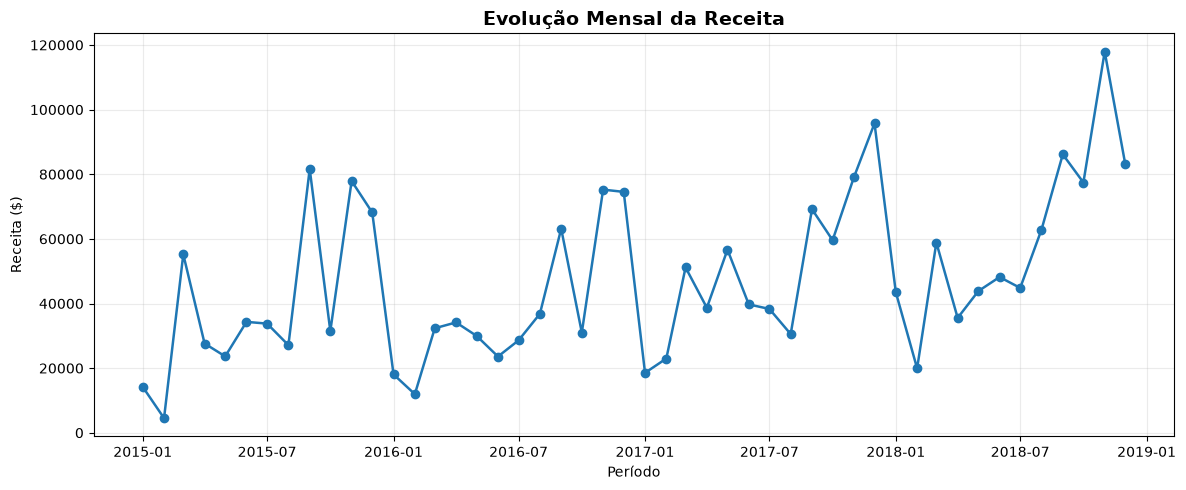

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o",
    linewidth=1.8
)

ax.set_title(
    "Evolução Mensal da Receita",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Período")
ax.set_ylabel("Receita ($)")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

A série apresenta variações relevantes entre os meses e indícios de crescimento ao longo do período, acompanhados por picos de receita em determinados momentos.

Embora alguns comportamentos possam sugerir recorrência sazonal, o histórico contém apenas quatro ciclos anuais. Por isso, a existência de sazonalidade não é assumida apenas pela inspeção visual e será tratada como uma hipótese a ser avaliada no processo de previsão.

## 2. Preparação para Forecasting

### 2.1 — Separação Temporal entre Treino e Teste

Para avaliar a capacidade de previsão fora da amostra, os últimos 12 meses da série são reservados como conjunto de teste.

A separação respeita a ordem cronológica dos dados: os primeiros 36 meses são utilizados para treinamento e os 12 meses finais permanecem desconhecidos para o modelo durante o ajuste.

Essa estratégia simula um cenário real de forecasting e evita vazamento de informação do futuro para o processo de treinamento.

In [5]:
test_horizon = 12

# Preserva a ordem temporal: os últimos 12 meses ficam isolados para
# simular previsões sobre um período ainda não observado pelo modelo.
train = monthly_revenue.iloc[:-test_horizon].copy()
test = monthly_revenue.iloc[-test_horizon:].copy()

print(f"Treino: {len(train)} meses")
print(f"Período de treino: {train.index.min().date()} a {train.index.max().date()}")

print()

print(f"Teste: {len(test)} meses")
print(f"Período de teste: {test.index.min().date()} a {test.index.max().date()}")

Treino: 36 meses
Período de treino: 2015-01-01 a 2017-12-01

Teste: 12 meses
Período de teste: 2018-01-01 a 2018-12-01


A divisão temporal mantém 36 meses para treinamento (2015–2017) e reserva todo o ano de 2018 para avaliação.

Diferentemente de uma divisão aleatória, essa abordagem preserva a sequência cronológica e impede que informações futuras sejam utilizadas durante o treinamento.

### 2.2 — Baseline de Previsão

Antes da aplicação de um modelo estatístico, é estabelecido um baseline sazonal para servir como referência de desempenho.

O método Seasonal Naive assume que a receita de cada mês será igual à observada no mesmo mês do ano anterior. Para uma série mensal, isso corresponde a uma defasagem sazonal de 12 meses.

O baseline fornece uma referência simples e interpretável que o modelo de forecasting deverá superar para demonstrar ganho preditivo.

In [6]:
seasonal_period = 12

# Utiliza os últimos 12 meses conhecidos (2017) como previsão para os
# 12 meses seguintes (2018), preservando o padrão do mesmo mês do ano anterior.
seasonal_naive = train.iloc[-seasonal_period:].copy()

# Reposiciona as previsões no índice do período de teste para permitir
# comparação direta entre previsão e valor realizado.
seasonal_naive.index = test.index
seasonal_naive.name = "Seasonal Naive"

baseline_comparison = pd.DataFrame({
    "Actual": test,
    "Seasonal Naive": seasonal_naive
})

baseline_comparison

,Actual,Seasonal Naive
Order Date,,
2018-01-01,43476.4740,18542.4910
2018-02-01,19920.9974,22978.8150
2018-03-01,58863.4128,51165.0590
2018-04-01,35541.9101,38679.7670
2018-05-01,43825.9822,56656.9080
2018-06-01,48190.7277,39724.4860
2018-07-01,44825.1040,38320.7830
2018-08-01,62837.8480,30542.2003
2018-09-01,86152.8880,69193.3909


O baseline reproduz para 2018 os valores observados nos mesmos meses de 2017. Dessa forma, ele incorpora uma estrutura sazonal anual sem estimar parâmetros adicionais.

Essa abordagem funciona como uma referência mínima de desempenho: um modelo mais sofisticado deve apresentar erros inferiores ao Seasonal Naive para justificar sua utilização.

In [7]:
baseline_metrics = calculate_forecast_metrics(
    actual=test,
    predicted=seasonal_naive
)

baseline_metrics_display = pd.DataFrame({
    "Modelo": ["Seasonal Naive"],
    "MAE": [f"${baseline_metrics['mae']:,.2f}"],
    "RMSE": [f"${baseline_metrics['rmse']:,.2f}"],
    "MAPE": [f"{baseline_metrics['mape']:.2%}"]
})

baseline_metrics_display

,Modelo,MAE,RMSE,MAPE
0,Seasonal Naive,"$15,444.18","$18,932.10",24.86%


O Seasonal Naive apresenta MAE de $15.444,18, indicando um desvio absoluto médio de aproximadamente $15,4 mil por mês.

O RMSE de $18.932,10, superior ao MAE, indica a presença de meses com erros de maior magnitude. O MAPE de 24,86% representa o erro percentual absoluto médio do baseline ao longo dos 12 meses de teste.

Esses valores constituem a referência para avaliar o ganho preditivo do Holt-Winters.

## 3. Modelagem e Avaliação

### 3.1 — Modelo de Forecasting

O baseline sazonal estabelece uma referência simples baseada na repetição do comportamento observado no mesmo mês do ano anterior.

Nesta etapa, será utilizado um modelo de suavização exponencial Holt-Winters, adequado para séries temporais que podem apresentar componentes de nível, tendência e sazonalidade.

O modelo será ajustado exclusivamente aos 36 meses do conjunto de treino. As previsões serão então geradas para os 12 meses do conjunto de teste, preservando a avaliação fora da amostra.

A especificação adotada utiliza tendência aditiva e sazonalidade aditiva com período de 12 meses. Isso permite representar mudanças no nível da receita e oscilações sazonais anuais em valores absolutos.

A escolha mantém o modelo relativamente simples diante de uma série com apenas 36 observações disponíveis para treinamento e três ciclos anuais completos.

In [8]:
# Modelo aditivo: tendência e sazonalidade são representadas como
# variações absolutas de receita, em vez de variações proporcionais.
hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

# Os parâmetros de suavização são estimados exclusivamente com os
# 36 meses de treino, mantendo 2018 fora do processo de ajuste.
hw_fit = hw_model.fit(
    optimized=True
)

# Gera exatamente 12 previsões, correspondentes ao horizonte reservado
# para avaliação fora da amostra.
hw_forecast = hw_fit.forecast(
    steps=len(test)
)

hw_forecast.name = "Holt-Winters"

print(f"Observações utilizadas no treino: {len(train)}")
print(f"Previsões geradas: {len(hw_forecast)}")
print(
    f"Período previsto: "
    f"{hw_forecast.index.min().date()} a "
    f"{hw_forecast.index.max().date()}"
)

Observações utilizadas no treino: 36
Previsões geradas: 12
Período previsto: 2018-01-01 a 2018-12-01


### 3.2 — Avaliação Fora da Amostra

As previsões do Holt-Winters são comparadas com os valores reais observados no conjunto de teste.

A avaliação utiliza as mesmas métricas aplicadas ao baseline — MAE, RMSE e MAPE — garantindo uma comparação consistente entre as abordagens.

In [9]:
hw_metrics = calculate_forecast_metrics(
    actual=test,
    predicted=hw_forecast
)

hw_metrics_display = pd.DataFrame({
    "Modelo": ["Holt-Winters"],
    "MAE": [f"${hw_metrics['mae']:,.2f}"],
    "RMSE": [f"${hw_metrics['rmse']:,.2f}"],
    "MAPE": [f"{hw_metrics['mape']:.2%}"]
})

hw_metrics_display

,Modelo,MAE,RMSE,MAPE
0,Holt-Winters,"$11,384.97","$12,429.52",22.73%


O Holt-Winters apresentou MAE de $11.384,97, RMSE de $12.429,52 e MAPE de 22,73%.

As três métricas ficaram abaixo das obtidas pelo Seasonal Naive. A redução do RMSE é particularmente relevante porque indica menor impacto dos maiores erros mensais, enquanto a redução do MAE mostra melhoria também no erro médio em valores monetários.

### 3.3 — Comparação com o Baseline

O desempenho do Holt-Winters é comparado diretamente com o Seasonal Naive utilizando o mesmo período de teste e as mesmas métricas de erro.

Valores menores indicam maior precisão preditiva.

In [10]:
model_comparison = pd.DataFrame({
    "Modelo": [
        "Seasonal Naive",
        "Holt-Winters"
    ],
    "MAE": [
        baseline_metrics["mae"],
        hw_metrics["mae"]
    ],
    "RMSE": [
        baseline_metrics["rmse"],
        hw_metrics["rmse"]
    ],
    "MAPE": [
        baseline_metrics["mape"],
        hw_metrics["mape"]
    ]
})

model_comparison_display = model_comparison.copy()

model_comparison_display["MAE"] = (
    model_comparison_display["MAE"]
    .map(lambda value: f"${value:,.2f}")
)

model_comparison_display["RMSE"] = (
    model_comparison_display["RMSE"]
    .map(lambda value: f"${value:,.2f}")
)

model_comparison_display["MAPE"] = (
    model_comparison_display["MAPE"]
    .map(lambda value: f"{value:.2%}")
)

model_comparison_display

,Modelo,MAE,RMSE,MAPE
0,Seasonal Naive,"$15,444.18","$18,932.10",24.86%
1,Holt-Winters,"$11,384.97","$12,429.52",22.73%


In [11]:
# Quantifica a redução relativa do erro do Holt-Winters em relação
# ao baseline. Valores positivos representam ganho preditivo.
mae_improvement = (
    (baseline_metrics["mae"] - hw_metrics["mae"])
    / baseline_metrics["mae"]
)

rmse_improvement = (
    (baseline_metrics["rmse"] - hw_metrics["rmse"])
    / baseline_metrics["rmse"]
)

mape_improvement = (
    (baseline_metrics["mape"] - hw_metrics["mape"])
    / baseline_metrics["mape"]
)

print(f"Redução do MAE: {mae_improvement:.2%}")
print(f"Redução do RMSE: {rmse_improvement:.2%}")
print(f"Redução do MAPE: {mape_improvement:.2%}")

Redução do MAE: 26.28%
Redução do RMSE: 34.35%
Redução do MAPE: 8.58%


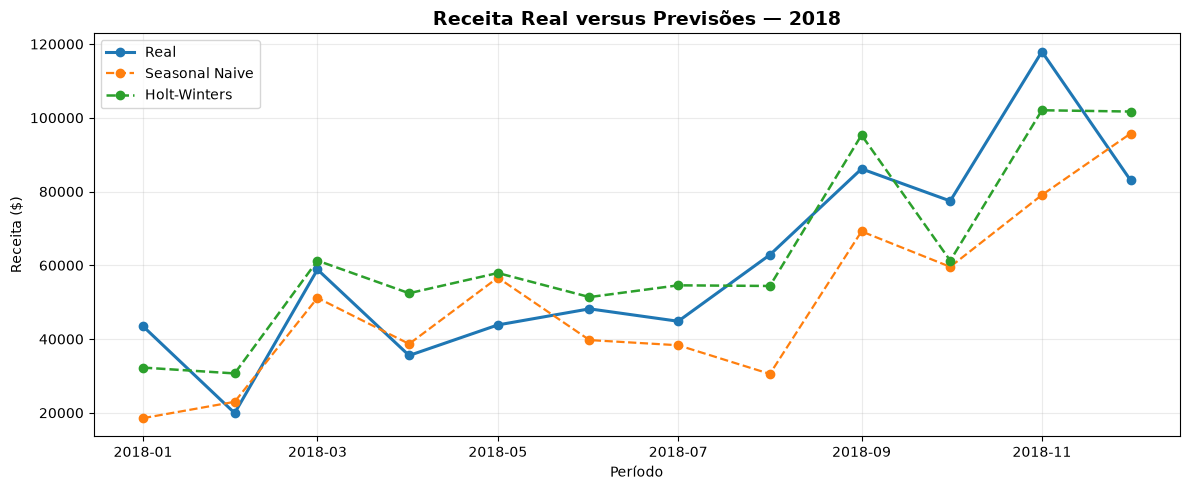

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=2.2,
    label="Real"
)

ax.plot(
    seasonal_naive.index,
    seasonal_naive.values,
    marker="o",
    linestyle="--",
    linewidth=1.6,
    label="Seasonal Naive"
)

ax.plot(
    hw_forecast.index,
    hw_forecast.values,
    marker="o",
    linestyle="--",
    linewidth=1.8,
    label="Holt-Winters"
)

ax.set_title(
    "Receita Real versus Previsões — 2018",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Período")
ax.set_ylabel("Receita ($)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

O Holt-Winters acompanha melhor o nível e a dinâmica geral da receita observada em 2018 quando comparado ao Seasonal Naive.

Ainda existem desvios relevantes em determinados meses, especialmente nos períodos de maior variação da receita. Isso reforça que o modelo captura parte da estrutura temporal da série, mas não elimina a incerteza associada às oscilações mensais.

A avaliação quantitativa confirma essa leitura: o Holt-Winters reduziu o MAE em 26,28%, o RMSE em 34,35% e o MAPE em 8,58% em relação ao baseline.

## 4. Previsão dos Próximos Períodos

### 4.1 — Modelo Final

Após a avaliação fora da amostra, o Holt-Winters é reajustado utilizando todo o histórico disponível de receita mensal.

Como os dados de 2018 já cumpriram seu papel na validação do modelo, eles passam a integrar o conjunto de treinamento final. Dessa forma, o modelo utiliza as 48 observações disponíveis entre 2015 e 2018 antes da geração das previsões futuras.

In [13]:
# Após a seleção do modelo pela avaliação fora da amostra, reajusta
# a mesma especificação utilizando todo o histórico disponível.
final_model = ExponentialSmoothing(
    monthly_revenue,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

final_fit = final_model.fit(
    optimized=True
)

print(f"Observações utilizadas no modelo final: {len(monthly_revenue)}")
print(
    f"Período utilizado: "
    f"{monthly_revenue.index.min().date()} a "
    f"{monthly_revenue.index.max().date()}"
)

Observações utilizadas no modelo final: 48
Período utilizado: 2015-01-01 a 2018-12-01


### 4.2 — Forecast de Receita

O modelo final é utilizado para gerar previsões para os 12 meses seguintes ao término do histórico disponível.

O horizonte de 12 meses mantém consistência com a janela utilizada na avaliação fora da amostra e corresponde a um ciclo anual completo.

Como não existem valores reais de 2019 na base analisada, essas estimativas representam previsões futuras e não podem ser avaliadas diretamente por MAE, RMSE ou MAPE.

In [14]:
forecast_horizon = 12

# Projeta um ciclo anual completo além do último período observado.
future_forecast = final_fit.forecast(
    steps=forecast_horizon
)

future_forecast.name = "Forecast"

forecast_table = future_forecast.to_frame()
forecast_table.index.name = "Month"

forecast_table

,Forecast
Month,
2019-01-01,49382.800954
2019-02-01,41589.003209
2019-03-01,71938.965250
2019-04-01,60859.950091
2019-05-01,68119.660255
2019-06-01,62698.788818
2019-07-01,66237.298660
2019-08-01,65234.825542
2019-09-01,105699.079491


O forecast projeta a continuidade do comportamento temporal aprendido pelo modelo para os 12 meses seguintes ao histórico.

As estimativas preservam diferenças mensais compatíveis com a estrutura aprendida pelo Holt-Winters, incluindo níveis mais elevados no final do ano. Como 2019 não está presente na base, esses valores representam projeções e não podem ser tratados como resultados realizados.

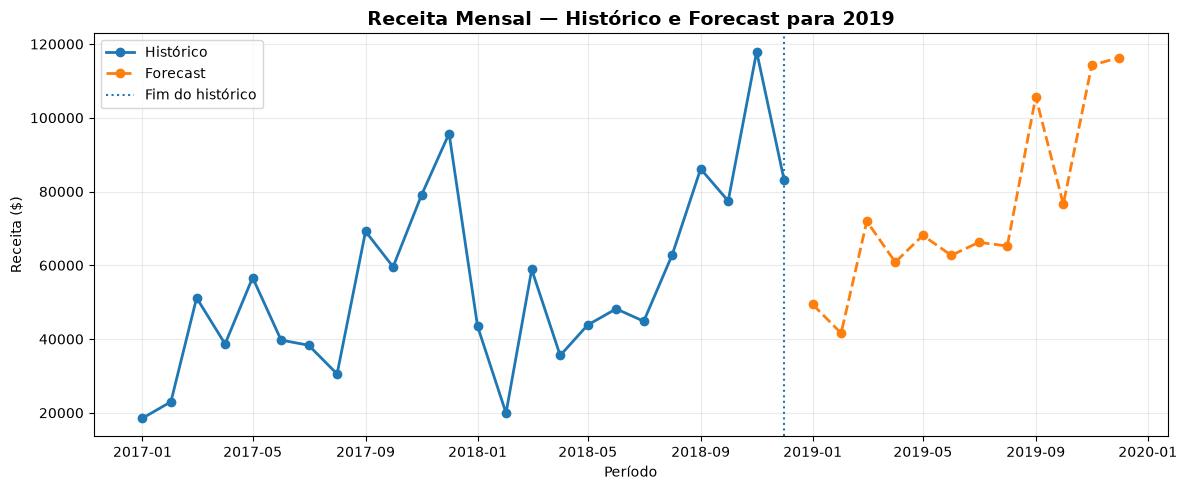

In [15]:
historical_window = monthly_revenue.loc["2017-01-01":]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    historical_window.index,
    historical_window.values,
    marker="o",
    linewidth=2,
    label="Histórico"
)

ax.plot(
    future_forecast.index,
    future_forecast.values,
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Forecast"
)

ax.axvline(
    monthly_revenue.index.max(),
    linestyle=":",
    linewidth=1.5,
    label="Fim do histórico"
)

ax.set_title(
    "Receita Mensal — Histórico e Forecast para 2019",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Período")
ax.set_ylabel("Receita ($)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [16]:
forecast_total = future_forecast.sum()
forecast_monthly_average = future_forecast.mean()

forecast_peak_month = future_forecast.idxmax()
forecast_peak_value = future_forecast.max()

forecast_low_month = future_forecast.idxmin()
forecast_low_value = future_forecast.min()

print(f"Receita projetada para 2019: ${forecast_total:,.2f}")
print(f"Média mensal projetada: ${forecast_monthly_average:,.2f}")

print()

print(
    f"Maior previsão mensal: "
    f"{forecast_peak_month.strftime('%Y-%m')} "
    f"(${forecast_peak_value:,.2f})"
)

print(
    f"Menor previsão mensal: "
    f"{forecast_low_month.strftime('%Y-%m')} "
    f"(${forecast_low_value:,.2f})"
)

Receita projetada para 2019: $898,941.86
Média mensal projetada: $74,911.82

Maior previsão mensal: 2019-12 ($116,334.30)
Menor previsão mensal: 2019-02 ($41,589.00)


Para 2019, o modelo projeta receita anual de $898.941,86 e média mensal de $74.911,82.

Dezembro apresenta a maior previsão mensal ($116.334,30), enquanto fevereiro apresenta a menor ($41.589,00). Essas diferenças refletem os componentes de tendência e sazonalidade estimados a partir do histórico disponível.

## 5. Síntese da Análise Preditiva

### 5.1 — Principais Achados

- A série mensal foi construída com 48 observações entre janeiro de 2015 e dezembro de 2018, sem lacunas temporais e com reconciliação integral da receita.

- A avaliação fora da amostra utilizou os primeiros 36 meses para treinamento e os 12 meses de 2018 como período de teste.

- O Seasonal Naive apresentou MAE de $15.444,18, RMSE de $18.932,10 e MAPE de 24,86%.

- O Holt-Winters apresentou desempenho superior no período de teste, com MAE de $11.384,97, RMSE de $12.429,52 e MAPE de 22,73%.

- Em relação ao baseline, o Holt-Winters reduziu o MAE em 26,28%, o RMSE em 34,35% e o MAPE em 8,58%.

- Após a validação, o modelo foi reajustado com todo o histórico disponível e utilizado para projetar os 12 meses de 2019.

- A receita projetada para 2019 é de $898.941,86, equivalente a uma média mensal de $74.911,82. O maior valor mensal previsto ocorre em dezembro ($116.334,30) e o menor em fevereiro ($41.589,00).

### 5.2 — Limitações

- O histórico disponível contém apenas 48 observações mensais e quatro ciclos anuais, limitando a quantidade de informação disponível para estimação de padrões temporais.

- A avaliação foi realizada em uma única janela temporal de 12 meses. Portanto, o desempenho observado em 2018 não garante o mesmo nível de erro em períodos futuros.

- O modelo utiliza exclusivamente o comportamento histórico da receita. Variáveis externas capazes de influenciar vendas, como preços, promoções, condições econômicas, disponibilidade de produtos ou mudanças comerciais, não estão presentes na modelagem.

- As previsões para 2019 representam estimativas condicionadas aos padrões observados entre 2015 e 2018 e não devem ser interpretadas como valores realizados ou metas garantidas.

- A incorporação de novos dados ao longo do tempo permitiria reestimar o modelo, reavaliar sua performance e verificar a estabilidade dos padrões identificados.